# HAM10000 Skin Lesion Classification

## CNN Model Development

### Objective
Build and train a custom Convolutional Neural Network
to classify HAM10000 skin lesion images into seven classes.

### Tasks
1. Import required libraries.
2. Load preprocessed datasets.
3. Build a custom CNN architecture.
4. Add Batch Normalization and Dropout.
5. Compile the model.
6. Configure training callbacks.
7. Train the CNN model.
8. Visualize training performance.
9. Save the trained model.

In [1]:
# Import libraries for deep learning

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from pathlib import Path

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    BatchNormalization,
    Activation,
    GlobalAveragePooling2D,
    Dense,
    Dropout
)

from tensorflow.keras.optimizers import Adam

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Set visualization style
sns.set_style("whitegrid")

# Set random seed for reproducibility
tf.keras.utils.set_random_seed(42)

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
Libraries imported successfully!


In [2]:
# Define project directories

PROJECT_DIR = Path("..")
OUTPUT_DIR = PROJECT_DIR / "outputs"
MODEL_DIR = PROJECT_DIR / "models"

# Create model directory
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Define CSV file paths
TRAIN_PATH = OUTPUT_DIR / "train.csv"
VAL_PATH = OUTPUT_DIR / "validation.csv"
TEST_PATH = OUTPUT_DIR / "test.csv"

# Define image configuration
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 7
EPOCHS = 30

# Define class names
CLASS_NAMES = [
    "akiec",
    "bcc",
    "bkl",
    "df",
    "mel",
    "nv",
    "vasc"
]

print("Configuration completed!")

Configuration completed!


In [3]:
# Load training, validation, and testing metadata

train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VAL_PATH)
test_df = pd.read_csv(TEST_PATH)

# Display dataset sizes
print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

# Display sample training records
train_df.head()

Training samples: 5942
Validation samples: 2059
Testing samples: 2014


,lesion_id,image_id,dx,dx_type,age,sex,localization,image_path,label,split
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,..\data\HAM10000_images_part_1\ISIC_0027419.jpg,2,Training
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,..\data\HAM10000_images_part_1\ISIC_0025030.jpg,2,Training
2,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,..\data\HAM10000_images_part_2\ISIC_0031633.jpg,2,Training
3,HAM_0001466,ISIC_0027850,bkl,histo,75.0,male,ear,..\data\HAM10000_images_part_1\ISIC_0027850.jpg,2,Training
4,HAM_0002761,ISIC_0029176,bkl,histo,60.0,male,face,..\data\HAM10000_images_part_1\ISIC_0029176.jpg,2,Training


In [4]:
# Create image augmentation for training data

train_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.15,
    horizontal_flip=True,
    vertical_flip=True
)

# Validation data uses only normalization

validation_datagen = ImageDataGenerator(
    rescale=1.0 / 255
)

# Create training generator

train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col="image_path",
    y_col="dx",
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=CLASS_NAMES,
    shuffle=True,
    seed=42
)

# Create validation generator

validation_generator = validation_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col="image_path",
    y_col="dx",
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=CLASS_NAMES,
    shuffle=False
)

print("Image generators created successfully!")

Found 5942 validated image filenames belonging to 7 classes.
Found 2059 validated image filenames belonging to 7 classes.
Image generators created successfully!


## Custom CNN Architecture

The CNN contains four convolutional blocks.

Each block contains:
- Conv2D: Extracts image features.
- BatchNormalization: Stabilizes activations.
- ReLU: Adds non-linearity.
- MaxPooling2D: Reduces spatial dimensions.

After feature extraction:
- GlobalAveragePooling2D summarizes feature maps.
- Dense layer learns class-specific patterns.
- Dropout helps reduce overfitting.
- Softmax predicts probabilities for seven classes.

In [5]:
# Define a reusable convolutional block

def convolution_block(model, filters):

    # Extract image features
    model.add(
        Conv2D(
            filters=filters,
            kernel_size=(3, 3),
            padding="same",
            use_bias=False
        )
    )

    # Normalize layer activations
    model.add(BatchNormalization())

    # Apply ReLU activation
    model.add(Activation("relu"))

    # Reduce spatial dimensions
    model.add(MaxPooling2D(pool_size=(2, 2)))


# Create the CNN model

model = Sequential(name="HAM10000_Custom_CNN")

# Define input shape
model.add(
    Input(shape=(224, 224, 3))
)

# First convolutional block
convolution_block(model, 32)

# Second convolutional block
convolution_block(model, 64)

# Third convolutional block
convolution_block(model, 128)

# Fourth convolutional block
convolution_block(model, 256)

# Convert feature maps into a feature vector
model.add(GlobalAveragePooling2D())

# Fully connected classification layer
model.add(Dense(256, activation="relu"))

# Reduce overfitting
model.add(Dropout(0.5))

# Output layer for seven diagnostic classes
model.add(
    Dense(
        NUM_CLASSES,
        activation="softmax"
    )
)

print("Custom CNN model created successfully!")

Custom CNN model created successfully!


In [6]:
# Display the model architecture

model.summary()

Model: "HAM10000_Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 224, 224, 32)        │             864 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 224, 224, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation (Activation)              │ (None, 224, 224, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 112, 112, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 112, 112, 64)        │          18,432 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 112, 112, 64)        │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_1 (Activation)            │ (None, 112, 112, 64)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 56, 56, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 56, 56, 128)         │          73,728 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 56, 56, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_2 (Activation)            │ (None, 56, 56, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 28, 28, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 28, 28, 256)         │         294,912 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 28, 28, 256)         │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_3 (Activation)            │ (None, 28, 28, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 14, 14, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 256)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │          65,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │              

 Total params: 457,447 (1.75 MB)

 Trainable params: 456,487 (1.74 MB)

 Non-trainable params: 960 (3.75 KB)

In [7]:
# Save and visualize CNN architecture

tf.keras.utils.plot_model(
    model,
    to_file=str(MODEL_DIR / "custom_cnn_architecture.png"),
    show_shapes=True,
    show_layer_names=True,
    expand_nested=True
)

print("Model architecture visualization saved!")

You must install graphviz (see instructions at https://graphviz.gitlab.io/download/) for `plot_model` to work.
Model architecture visualization saved!


In [8]:
# Compile the CNN model

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

print("Model compiled successfully!")

Model compiled successfully!


## Training Callbacks

### EarlyStopping
Stops training when validation loss does not improve.

### ModelCheckpoint
Saves the best model based on validation loss.

### ReduceLROnPlateau
Reduces learning rate when validation loss stops improving.

In [9]:
# Save the best model during training

checkpoint = ModelCheckpoint(
    filepath=str(MODEL_DIR / "custom_cnn_best.keras"),
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

# Stop training when validation loss does not improve

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Reduce learning rate when validation loss plateaus

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

callbacks = [
    checkpoint,
    early_stopping,
    reduce_lr
]

print("Callbacks configured successfully!")

Callbacks configured successfully!


In [10]:
# Train the custom CNN model

history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/30
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6654 - loss: 0.9602 - precision: 0.7751 - recall: 0.5476
Epoch 1: val_loss improved from None to 1.43082, saving model to ..\models\custom_cnn_best.keras

Epoch 1: finished saving model to ..\models\custom_cnn_best.keras
186/186 ━━━━━━━━━━━━━━━━━━━━ 504s 3s/step - accuracy: 0.6654 - loss: 0.9602 - precision: 0.7751 - recall: 0.5476 - val_accuracy: 0.6343 - val_loss: 1.4308 - val_precision: 0.9733 - val_recall: 0.0709 - learning_rate: 0.0010
Epoch 2/30
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6871 - loss: 0.8711 - precision: 0.7976 - recall: 0.5729
Epoch 2: val_loss improved from 1.43082 to 1.21909, saving model to ..\models\custom_cnn_best.keras

Epoch 2: finished saving model to ..\models\custom_cnn_best.keras
186/186 ━━━━━━━━━━━━━━━━━━━━ 388s 2s/step - accuracy: 0.6871 - loss: 0.8711 - precision: 0.7976 - recall: 0.5729 - val_accuracy: 0.6226 - val_loss: 1.2191 - val_precision: 0.8243 - val_recall: 0.2802 -

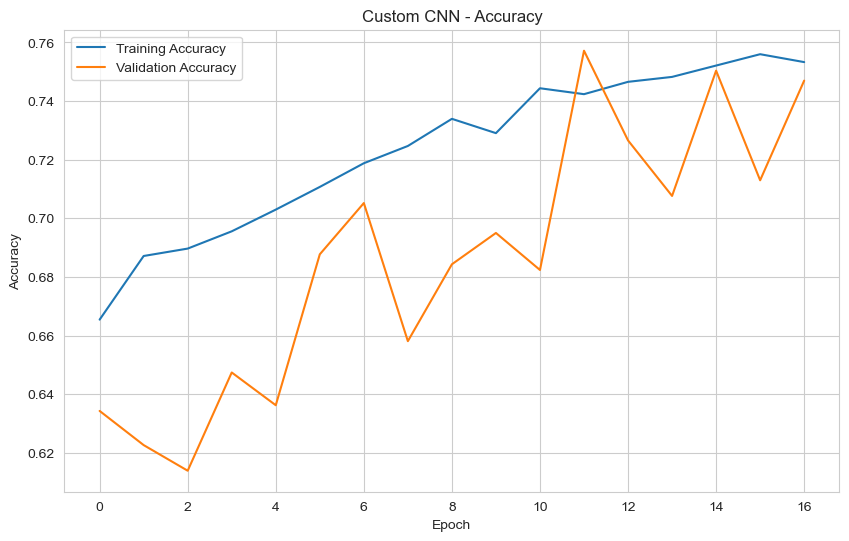

In [11]:
# Extract accuracy values

train_accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]

# Plot training and validation accuracy

plt.figure(figsize=(10, 6))

plt.plot(
    train_accuracy,
    label="Training Accuracy"
)

plt.plot(
    val_accuracy,
    label="Validation Accuracy"
)

plt.title("Custom CNN - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

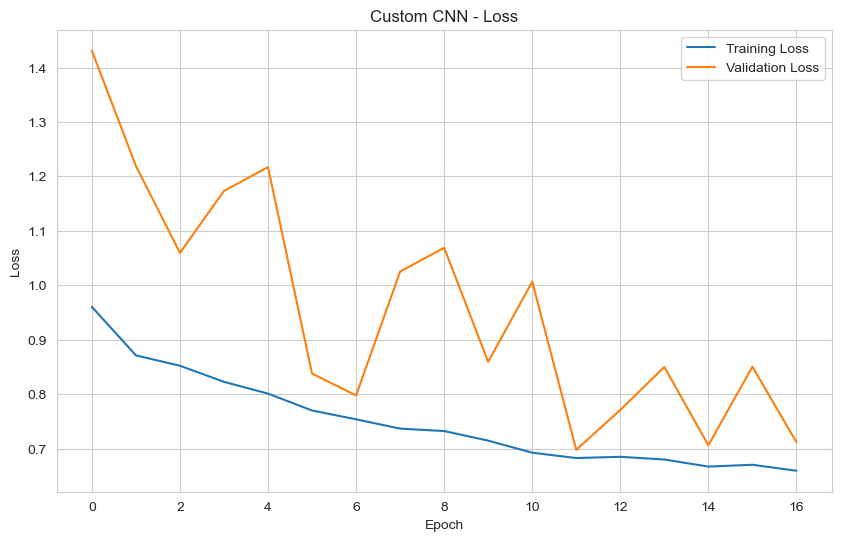

In [12]:
# Extract loss values

train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

# Plot training and validation loss

plt.figure(figsize=(10, 6))

plt.plot(
    train_loss,
    label="Training Loss"
)

plt.plot(
    val_loss,
    label="Validation Loss"
)

plt.title("Custom CNN - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

In [13]:
# Identify epoch with minimum validation loss

best_epoch = np.argmin(val_loss)

print("Best Epoch:", best_epoch + 1)

print(
    "Best Validation Loss:",
    round(val_loss[best_epoch], 4)
)

print(
    "Validation Accuracy at Best Epoch:",
    round(val_accuracy[best_epoch], 4)
)

Best Epoch: 12
Best Validation Loss: 0.6976
Validation Accuracy at Best Epoch: 0.7572


In [14]:
# Save the final model with restored best weights

FINAL_MODEL_PATH = MODEL_DIR / "skin_lesion_custom_cnn.keras"

model.save(FINAL_MODEL_PATH)

print("Final model saved at:", FINAL_MODEL_PATH)

Final model saved at: ..\models\skin_lesion_custom_cnn.keras


In [15]:
# Convert training history into a DataFrame

history_df = pd.DataFrame(history.history)

# Save training history
history_df.to_csv(
    OUTPUT_DIR / "custom_cnn_training_history.csv",
    index=False
)

print("Training history saved successfully!")

Training history saved successfully!


## Conclusion

A custom CNN model was developed and trained using
the HAM10000 skin lesion image dataset.

The model includes:
- Four convolutional blocks.
- Batch Normalization.
- ReLU activation.
- Max Pooling.
- Global Average Pooling.
- Dense classification layer.
- Dropout regularization.
- EarlyStopping and learning rate scheduling.

Training and validation performance were visualized.

The best model was saved for further evaluation.
